# Employee Attrition Prediction

Revised from Nivedha Sivakumar's saved learning project. Original intent and model families are retained.

## Review changes
- Removed unused TensorFlow and patsy dependencies
- Replaced arbitrary category numbers with training-fitted one-hot encoding
- Added scaling, imputation, stratified split, baseline and held-out metrics
- Removed raw employee previews and invalid synthetic prediction example

Data files are excluded from GitHub; use authorized local copies. Evaluation is educational and does not establish real-world suitability.

## Results and limitations

The model detected only 1 of 71 observed departures in the holdout at its default threshold; its accuracy is essentially equal to the majority baseline. ROC AUC is 0.636. Treat this as a limited baseline experiment, not a useful attrition screening system. Further work needs training-only threshold selection and evaluation on fresh data.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [3]:
dataframe=pd.read_csv("IBM Attrition Data.csv")

In [4]:
print('Rows:', len(dataframe))

Rows: 1470


In [5]:
names = dataframe.columns.values 
print(names)

<StringArray>
[                    'Age',               'Attrition',
              'Department',        'DistanceFromHome',
               'Education',          'EducationField',
 'EnvironmentSatisfaction',         'JobSatisfaction',
           'MaritalStatus',           'MonthlyIncome',
      'NumCompaniesWorked',         'WorkLifeBalance',
          'YearsAtCompany']
Length: 13, dtype: str


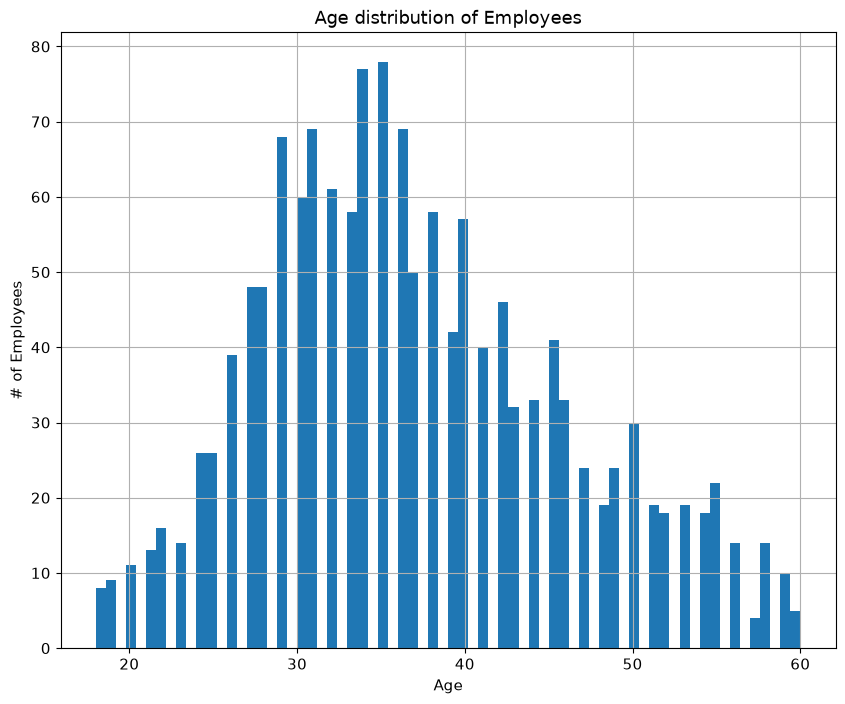

In [6]:
# histogram for age
plt.figure(figsize=(10,8))
dataframe['Age'].hist(bins=70)
plt.title("Age distribution of Employees")
plt.xlabel("Age")
plt.ylabel("# of Employees")
plt.show()

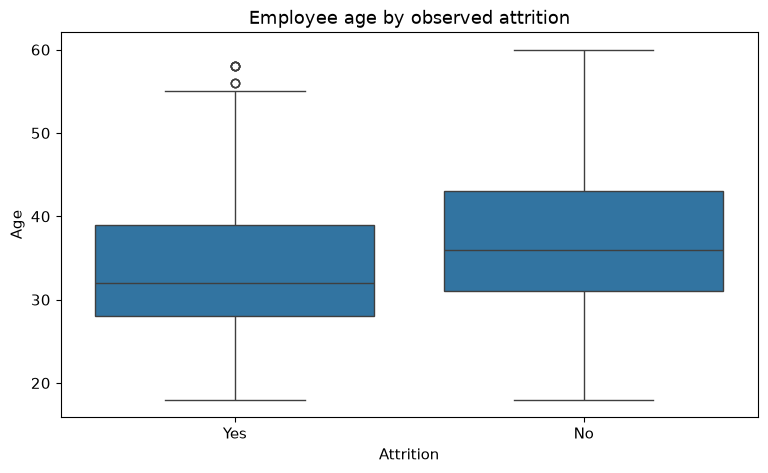

In [7]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=dataframe, x='Attrition', y='Age')
plt.title('Employee age by observed attrition')
plt.show()

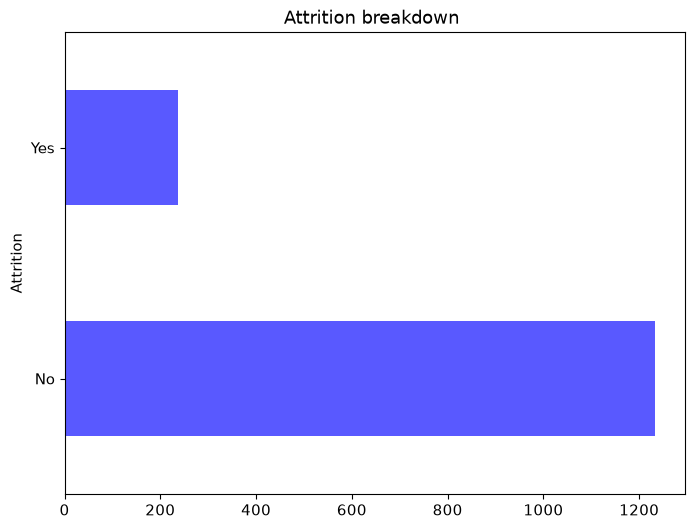

In [8]:
# explore data for Left employees breakdown
plt.figure(figsize=(8,6))
dataframe.Attrition.value_counts().plot(kind='barh',color='blue',alpha=.65)
plt.title("Attrition breakdown ")
plt.show()

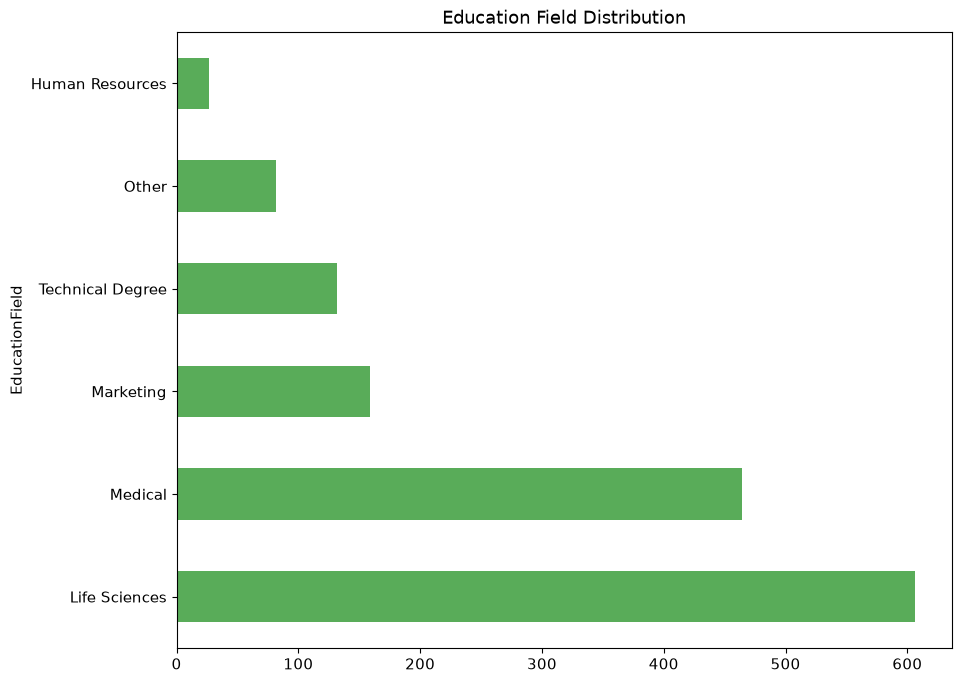

In [9]:
# explore data for Education Field distribution
plt.figure(figsize=(10,8))
dataframe.EducationField.value_counts().plot(kind='barh',color='g',alpha=.65)
plt.title("Education Field Distribution")
plt.show()

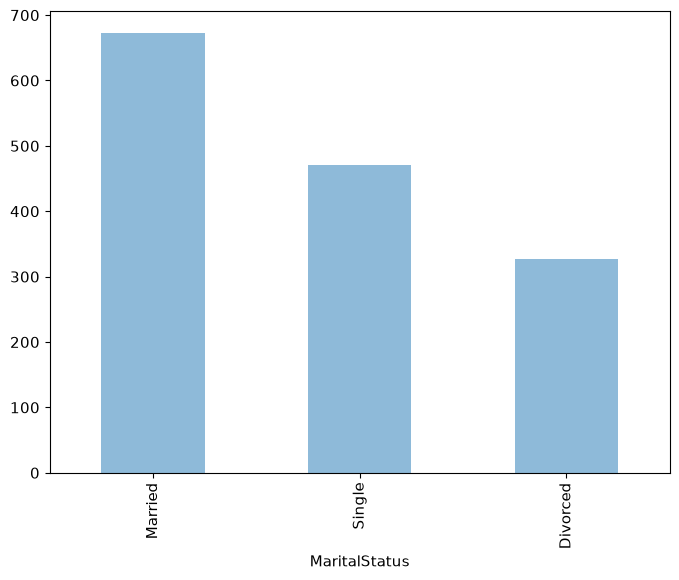

In [10]:
# explore data for Marital Status
plt.figure(figsize=(8,6))
dataframe.MaritalStatus.value_counts().plot(kind='bar',alpha=.5)
plt.show()

In [11]:
dataframe.describe()

In [12]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1470 non-null   int64
 1   Attrition                1470 non-null   str  
 2   Department               1470 non-null   str  
 3   DistanceFromHome         1470 non-null   int64
 4   Education                1470 non-null   int64
 5   EducationField           1470 non-null   str  
 6   EnvironmentSatisfaction  1470 non-null   int64
 7   JobSatisfaction          1470 non-null   int64
 8   MaritalStatus            1470 non-null   str  
 9   MonthlyIncome            1470 non-null   int64
 10  NumCompaniesWorked       1470 non-null   int64
 11  WorkLifeBalance          1470 non-null   int64
 12  YearsAtCompany           1470 non-null   int64
dtypes: int64(9), str(4)
memory usage: 149.4 KB


In [13]:
dataframe.columns

In [14]:
dataframe.std(numeric_only=True)

In [15]:
dataframe['Attrition'].value_counts()

In [16]:
dataframe['Attrition'].dtypes

## Train and evaluate logistic regression
The original six predictors are retained. Split before fitting categorical encoding and scaling; use a stratified holdout and a majority-class baseline.

Majority baseline accuracy: 0.8390022675736961
              precision    recall  f1-score   support

      Stayed       0.84      1.00      0.91       370
        Left       0.50      0.01      0.03        71

    accuracy                           0.84       441
   macro avg       0.67      0.51      0.47       441
weighted avg       0.79      0.84      0.77       441

ROC AUC: 0.6358774267224969
Average precision: 0.2715578114388346


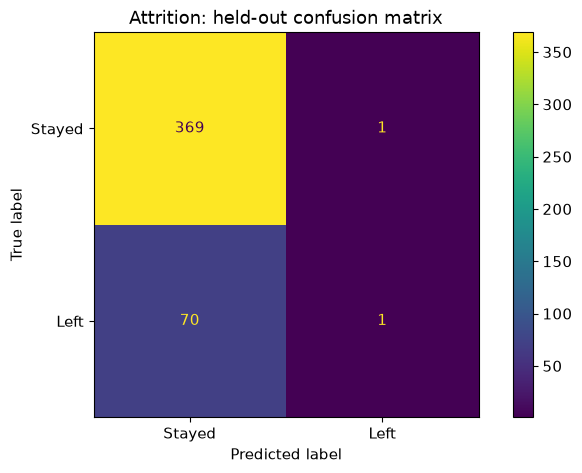

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
features = ['Age', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'YearsAtCompany']
X = dataframe[features].copy()
y = dataframe['Attrition'].map({'No': 0, 'Yes': 1})
assert y.notna().all(), 'Unexpected target labels'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
numeric = ['Age', 'DistanceFromHome', 'Education', 'YearsAtCompany']
categorical = ['Department', 'EducationField']
preprocess = ColumnTransformer([
    ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
    ('category', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), categorical)
])
model = make_pipeline(preprocess, LogisticRegression(max_iter=2000, random_state=42))
model.fit(X_train, y_train)
predicted = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Majority baseline accuracy:', baseline.score(X_test, y_test))
print(classification_report(y_test, predicted, target_names=['Stayed', 'Left'], zero_division=0))
print('ROC AUC:', roc_auc_score(y_test, probabilities))
print('Average precision:', average_precision_score(y_test, probabilities))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=['Stayed', 'Left'])
plt.title('Attrition: held-out confusion matrix')
plt.show()
